# Analisa data: DarGlobal & Wasalt

Notebook ini hanya **membaca** `data/` (snapshot 19–20 Nov 2026) untuk memahami bentuk dan kualitas data
sebelum dipakai chatbot. Tidak ada file data yang diubah.

1. DarGlobal (`darglobal_pages.json`): kolom, isi teks, masalah kualitas, uji ekstraksi kolom terstruktur
2. Wasalt (`wasalt_listings.json`): kolom, nilai kosong, distribusi, harga & outlier
3. Ringkasan temuan

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

DATA = Path("..") / "data" if Path("../data").exists() else Path("data")
dg = pd.DataFrame(json.loads((DATA / "darglobal_pages.json").read_text()))
ws = pd.DataFrame(json.loads((DATA / "wasalt_listings.json").read_text()))
print("DarGlobal:", dg.shape, "| Wasalt:", ws.shape)

DarGlobal: (60, 8) | Wasalt: (1307, 22)


## 1. DarGlobal

### 1.1 Kolom dan tipe data

In [2]:
dg.info()

<class 'pandas.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   kind         60 non-null     str  
 1   url          60 non-null     str  
 2   status       60 non-null     int64
 3   title        60 non-null     str  
 4   description  60 non-null     str  
 5   h1           60 non-null     str  
 6   text         60 non-null     str  
 7   via          7 non-null      str  
dtypes: int64(1), str(7)
memory usage: 3.9 KB


In [3]:
dg.head(3)

,kind,url,status,title,description,h1,text,via
0,project,https://darglobal.co.uk/trump-international-hotel-and-tower-dubai,200,Trump International Hotel & Tower Dubai | DarGlobal,The Middle East's first Trump hotel and residences in Dubai. Every unit has sea or Burj Khalifa views. World's highe...,Trump International Hotel & Tower Dubai,Gallery\nTrump International Hotel & Tower Dubai\nDubai | UAE\nDubai\nUAE\nPROPERTY TYPEBranded Hotel & Residential ...,NaN
1,project,https://darglobal.co.uk/d-villas-at-jge,200,D-Villas | Jumeirah Golf Estates Villas Dubai UAE | DarGlobal,Discover luxury living at D-Villas in Jumeirah Golf Estates — Dubai’s premier golf destination offering world-class ...,D-Villas At Jumeirah Golf Estates,Gallery\nD-Villas At Jumeirah Golf Estates\nDubai | UAE\nDubai\nUAE\nProperty TypeLuxury Villas\nProperty Type\nLuxu...,NaN
2,project,https://darglobal.co.uk/the-astera,200,"The Astera, Interiors by Aston Martin | Al Marjan Island RAK","The Astera on Al Marjan Island, RAK combines Aston Martin interiors with direct beach access. 1-3 bed residences and...","The Astera, Interiors by Aston Martin","Gallery\nThe Astera, Interiors by Aston Martin\nAl Marjan Island | RAK\nAl Marjan Island\nRAK\nProperty TypeBeach Re...",NaN


### 1.2 Jenis halaman dan nilai kosong

In [4]:
display(dg["kind"].value_counts().rename("jumlah halaman"))
kosong = pd.DataFrame({
    "kosong / null": [(dg[c].isna() | (dg[c].astype(str).str.strip() == "")).sum() for c in dg.columns]
}, index=dg.columns)
display(kosong)
print("Status HTTP:", dg["status"].value_counts().to_dict())
print("Kolom via:", dg["via"].value_counts(dropna=False).to_dict())

kind
project    38
general    22
Name: jumlah halaman, dtype: int64

,kosong / null
kind,0
url,0
status,0
title,9
description,17
h1,8
text,0
via,53


Status HTTP: {200: 60}
Kolom via: {nan: 53, 'next_data': 7}


Halaman yang `title`-nya kosong:

In [5]:
dg.loc[dg["title"].str.strip() == "", ["kind", "url", "h1", "via"]]

,kind,url,h1,via
13,project,https://darglobal.co.uk/lp/trump-international-qatar,,next_data
30,project,https://darglobal.co.uk/trump-plaza/park-residences,,next_data
31,project,https://darglobal.co.uk/rayana/trump-mansions,,next_data
32,project,https://darglobal.co.uk/trump-plaza/executive-residences,,next_data
33,project,https://darglobal.co.uk/amaya/amaya-plots,,next_data
34,project,https://darglobal.co.uk/amaya/padel-living,,next_data
37,project,https://darglobal.co.uk/rayana/darglobal-mansions-fendi-casa,,next_data
42,general,https://darglobal.co.uk/luxury-golf-communities,BUILDING COMMUNITIES,NaN
58,general,https://darglobal.co.uk/partners/paramount,Paramount,NaN


### 1.3 Panjang teks per halaman

,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
general,22.0,3010.0,2489.0,171.0,1393.0,2708.0,3829.0,9903.0
project,38.0,5439.0,2519.0,1325.0,3690.0,5783.0,7413.0,10729.0


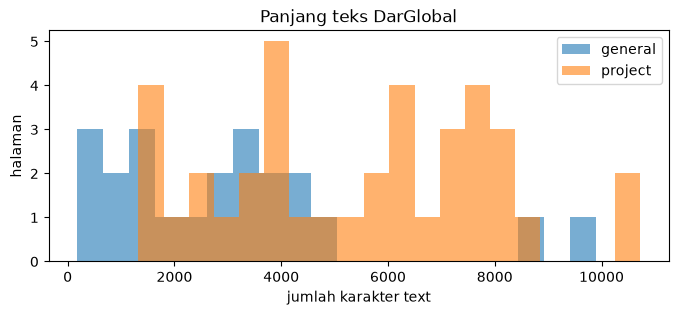

In [6]:
dg["text_len"] = dg["text"].str.len()
dg["n_lines"] = dg["text"].str.count("\n") + 1
display(dg.groupby("kind")["text_len"].describe().round(0))

fig, ax = plt.subplots(figsize=(8, 3))
for kind, sub in dg.groupby("kind"):
    ax.hist(sub["text_len"], bins=20, alpha=0.6, label=kind)
ax.set_xlabel("jumlah karakter text"); ax.set_ylabel("halaman"); ax.legend(); ax.set_title("Panjang teks DarGlobal")
plt.show()

In [7]:
dg.sort_values("text_len")[["kind", "h1", "text_len", "url"]].head(10)

,kind,h1,text_len,url
44,general,,171,https://darglobal.co.uk/exclusive-membership
42,general,BUILDING COMMUNITIES,225,https://darglobal.co.uk/luxury-golf-communities
41,general,"COMMERCIAL, REIMAGINED",342,https://darglobal.co.uk/commercial
40,general,"HOSPITALITY, REVISITED",816,https://darglobal.co.uk/hospitality
59,general,contact us,855,https://darglobal.co.uk/get-in-touch
8,project,Top Of the Astera,1325,https://darglobal.co.uk/one-of-one/top-of-the-astera
43,general,"Tokenization: Investing in the Future, Today",1374,https://darglobal.co.uk/tokenization
47,general,Investor Relations,1451,https://darglobal.co.uk/investor
58,general,Paramount,1506,https://darglobal.co.uk/partners/paramount
28,project,The Mulliner,1557,https://darglobal.co.uk/the-mulliner


### 1.4 Daftar halaman proyek

In [8]:
dg.loc[dg["kind"] == "project", ["h1", "url", "text_len"]].sort_values("url").reset_index(drop=True)

,h1,url,text_len
0,Sunrise Haven,https://darglobal.co.uk/Sunrise-Haven-Luxury-Villas,3810
1,Coastal Investment Villas,https://darglobal.co.uk/aida-coastal-investment-villas,4119
2,Trump Cliff Villas,https://darglobal.co.uk/aida-trump-international-cliff-villas,7861
3,"Trump International Hotel, Oman",https://darglobal.co.uk/aida-trump-international-hotel,8056
4,Trump Golf Villas,https://darglobal.co.uk/aida-trump-villas,7620
5,,https://darglobal.co.uk/amaya/amaya-plots,10512
6,,https://darglobal.co.uk/amaya/padel-living,7326
7,Amour Sans Detour,https://darglobal.co.uk/amour-sans-detour,3813
8,Amour Sans Detour 2,https://darglobal.co.uk/amour-sans-detour-2,3656
9,D-Villas At Jumeirah Golf Estates,https://darglobal.co.uk/d-villas-at-jge,2398


### 1.5 Contoh isi `text` mentah

Label dan nilai sering muncul dobel (`Property TypeSeafront Residences`, lalu `Property Type`, lalu `Seafront Residences`).

In [9]:
row = dg[dg["url"].str.endswith("/trump-tower-jeddah")].iloc[0]
print(row["text"][:1500])

Gallery
Trump Tower Jeddah
Saudi Arabia
Property TypeSeafront Residences
Property Type
Seafront Residences
Unit Type 1, 2, 3, 4 Bedroom Apartments & 3, 4 Bedroom Penthouses
Unit Type
1, 2, 3, 4 Bedroom Apartments & 3, 4 Bedroom Penthouses
LocationJeddah Corniche, Saudi Arabia
Location
Jeddah Corniche, Saudi Arabia
Number of Floors47
Number of Floors
47
Area (sqm)70 to 365
Area (sqm)
70 to 365
SEAFRONT RESIDENCES
The interiors of Trump Tower Jeddah seamlessly combine modern elegance with timeless sophistication, creating spaces that exude refinement and comfort. Designed to complement its breathtaking Red Sea views, each detail reflects a commitment to luxurious living.
Features & Amenities
Uninterrupted Sea Views
Prime Location On the Corniche
Strategic Investment Opportunity
Architectural Landmark
Trump Private Club
24/7 Concierge
Meeting Rooms
Cigar Lounge
Fine Dining
Pool
Kids Pool
Jacuzzi
Gym
Yoga Zone
Why INVEST
Saudi Arabia is undergoing a transformative economic revolution. Unde

Berapa baris yang merupakan gabungan label+nilai (`L[i] == L[i+1] + L[i+2]`), alias duplikat:

In [10]:
def concat_dups(text: str) -> int:
    L = [l.strip() for l in text.split("\n") if l.strip()]
    return sum(
        1 for i in range(len(L) - 2)
        if L[i] in (L[i + 1] + L[i + 2], L[i + 1] + " " + L[i + 2])
    )

dg["n_lines"] = dg["text"].map(lambda t: sum(1 for l in t.split("\n") if l.strip()))
dg["concat_dup"] = dg["text"].map(concat_dups)
dg["concat_dup_pct"] = (dg["concat_dup"] / dg["n_lines"] * 100).round(1)
display(dg.groupby("kind")[["concat_dup", "concat_dup_pct"]].describe().round(1))

concat_dup                                        concat_dup_pct                                       
             count  mean  std  min  25%   50%   75%   max          count  mean  std  min  25%   50%   75%   max
kind                                                                                                           
general       22.0   0.0  0.0  0.0  0.0   0.0   0.0   0.0           22.0   0.0  0.0  0.0  0.0   0.0   0.0   0.0
project       38.0  10.1  8.0  0.0  0.0  11.5  17.0  21.0           38.0  10.8  8.1  0.0  0.0  13.5  17.3  25.0

### 1.6 Sisa daftar negara di 7 halaman `via = next_data`

Awal teksnya berisi ±22 baris nama negara (sisa dropdown form), lalu menu navigasi berisi nama proyek LAIN (AIDA, Padel Living, Maldives, Trump Mansions, dll). Ini berbahaya untuk RAG: halaman satu proyek ikut menyebut proyek lain.

In [11]:
def leading_noise(text: str) -> int:
    """Jumlah baris awal sampai baris 'Wales' (akhir potongan daftar negara)."""
    L = [l.strip() for l in text.split("\n") if l.strip()]
    return L.index("Wales") + 1 if "Wales" in L[:60] else 0

def menu_hits(text: str) -> int:
    """Berapa nama proyek LAIN dari menu navigasi yang ikut masuk ke teks."""
    menu = ["Padel Living Residences", "Trump International Hotel & Resort Maldives", "Trump Mansions", "Amaya", "Altara"]
    return sum(1 for m in menu if m in text[:3000])

nd = dg[dg["via"] == "next_data"].copy()
nd["baris_negara_di_awal"] = nd["text"].map(leading_noise)
nd["nama_proyek_menu_di_awal"] = nd["text"].map(menu_hits)
nd["awal_teks"] = nd["text"].str[:150].str.replace("\n", " | ")
nd[["url", "text_len", "baris_negara_di_awal", "nama_proyek_menu_di_awal", "awal_teks"]]

,url,text_len,baris_negara_di_awal,nama_proyek_menu_di_awal,awal_teks
13,https://darglobal.co.uk/lp/trump-international-qatar,7939,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
30,https://darglobal.co.uk/trump-plaza/park-residences,7442,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
31,https://darglobal.co.uk/rayana/trump-mansions,7278,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
32,https://darglobal.co.uk/trump-plaza/executive-residences,7125,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
33,https://darglobal.co.uk/amaya/amaya-plots,10512,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
34,https://darglobal.co.uk/amaya/padel-living,7326,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...
37,https://darglobal.co.uk/rayana/darglobal-mansions-fendi-casa,8355,22,5,Canada | Christmas Island | Cocos | Curaçao | Finland | Isle of Man | Jersey | Kazakhstan | Norfolk Island | Pitcair...


### 1.7 Uji ekstraksi kolom terstruktur dari `text`

Mencoba mengambil field umum halaman proyek dengan pola `Label` + baris berikutnya = nilai.
Tujuannya melihat seberapa lengkap kalau data DarGlobal dibuat jadi tabel.

In [12]:
LABELS = {
    "property_type": r"property type",
    "unit_type": r"unit types?",
    "location": r"location",
    "status": r"status",
    "area": r"area.*|size.*",
    "floors": r"number of floors",
    "handover": r"(handover|completion|delivery).*",
    "price": r"(starting )?price.*",
}

def extract_fields(text: str) -> dict:
    lines = [l.strip() for l in text.split("\n") if l.strip()]
    found = {}
    for i, line in enumerate(lines[:-1]):
        for field, pat in LABELS.items():
            if field not in found and re.fullmatch(pat, line, flags=re.I):
                found[field] = lines[i + 1]
    return found

proj = dg[dg["kind"] == "project"].copy()
fields = pd.DataFrame(proj["text"].map(extract_fields).tolist(), index=proj.index)
proj_struct = pd.concat([proj[["h1", "url", "text"]], fields], axis=1)

coverage = fields.notna().sum().reindex(LABELS.keys(), fill_value=0)
display((coverage / len(proj) * 100).round(0).astype(int).rename("% halaman proyek terisi").to_frame())

,% halaman proyek terisi
property_type,79
unit_type,50
location,39
status,66
area,76
floors,3
handover,13
price,0


In [13]:
proj_struct.drop(columns=["url", "text"]).fillna("").reset_index(drop=True)

,h1,property_type,unit_type,status,area,location,handover,floors
0,Trump International Hotel & Tower Dubai,Branded Hotel & Residential Tower,"1, 2, 3 Bedroom Apartments & 4 Bedroom Duplex Penthouses",Under Development,AREA (SQFT),,,
1,D-Villas At Jumeirah Golf Estates,Luxury Villas,4 and 5-Bedroom Villas,Under Development,Area (SQFT),,,
2,"The Astera, Interiors by Aston Martin",Beach Residences and Villas,,Under Development,Area (SQFT),"Al Marjan Island, RAK",,
3,DG1,Residential Tower,"Studios, 1, 2, & 3-bedrooms",Under Development,Area (SQFT),,,
4,"Da Vinci Tower, Interiors by Pagani",Branded Residential Tower,"2, 3 & 4-bedrooms",Completed,Area (SQFT),,,
5,Urban Oasis by Missoni,Branded Residential Tower,,Completed and Sold out,Area (SQFT),,,
6,W Residences,Branded Residential Tower,"1, 2 & 3-bedrooms",Completed and Sold out,Area (SQFT),,,
7,The Pagani Penthouse,,,,,"The Pagani Penthouse is perched on The DaVinci Tower, which sits at the heart of Dubai’s cultural district, surround...",,
8,Top Of the Astera,,,,,"Nestled on Al Marjan Island, the Top of the Astera offers direct beach access, is minutes away from the Wynn Resort,...",,
9,"Tierra Viva, Design inspired by Automobili Lamborghini",Villa,Limited Collection Villas,Under Development,Area (SQM),,,


### 1.8 Negara/kota proyek

Pakai `location`, `h1`, `url`, dan 8 baris awal teks (biasanya `Kota | Negara`) untuk menebak negara. Yang tidak ketemu ditandai `?`.

In [14]:
COUNTRY_KEYS = {
    "Saudi Arabia": ["saudi", "riyadh", "jeddah", "diriyah", "rayana", "amaya", "wadi safar"],
    "UAE": ["dubai", "uae", "united arab emirates", "ras al khaimah", "rak", "abu dhabi"],
    "Qatar": ["qatar", "doha", "simaisma"],
    "Oman": ["oman", "muscat", "aida"],
    "Spain": ["spain", "marbella", "casares", "cortesin", "malaga"],
    "UK": ["london", "united kingdom", " uk"],
    "Maldives": ["maldives"],
    "Montenegro": ["montenegro"],
}

def guess_country(row) -> str:
    head = " ".join(row["text"].split("\n")[:8])  # baris awal biasanya 'Kota | Negara'
    hay = " ".join(str(x) for x in [row.get("location"), row["h1"], row["url"], head]).lower()
    for country, keys in COUNTRY_KEYS.items():
        if any(k in hay for k in keys):
            return country
    return "?"

proj_struct["country_guess"] = proj_struct.apply(guess_country, axis=1)
display(proj_struct["country_guess"].value_counts().rename("proyek"))
proj_struct.loc[proj_struct["country_guess"] == "?", ["h1", "url", "location"]]

country_guess
Oman            14
UAE              9
Saudi Arabia     8
Spain            3
Qatar            2
UK               2
Name: proyek, dtype: int64

,h1,url,location


## 2. Wasalt

### 2.1 Kolom dan tipe data

In [15]:
ws.info()

<class 'pandas.DataFrame'>
RangeIndex: 1307 entries, 0 to 1306
Data columns (total 22 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   id          1307 non-null   int64  
 1   source      1307 non-null   str    
 2   purpose     1307 non-null   str    
 3   title       1307 non-null   str    
 4   type        1307 non-null   str    
 5   main_type   1307 non-null   str    
 6   city        1307 non-null   str    
 7   district    1307 non-null   str    
 8   address     1307 non-null   str    
 9   price       1307 non-null   int64  
 10  currency    1307 non-null   str    
 11  rent_freq   483 non-null    object 
 12  bedrooms    1127 non-null   float64
 13  bathrooms   48 non-null     float64
 14  area_sqm    1307 non-null   str    
 15  age         1144 non-null   object 
 16  furnishing  35 non-null     str    
 17  amenities   1307 non-null   object 
 18  lat         1307 non-null   str    
 19  lon         1307 non-null   str    
 2

In [16]:
ws.head(3)

,id,source,purpose,title,type,main_type,city,district,address,price,...,bedrooms,bathrooms,area_sqm,age,furnishing,amenities,lat,lon,published,url
0,5807537,wasalt,sale,Floor 450 SQM with 6 Bedrooms,Floor,Residential,Alttayif,The Housing District,"The Housing District, Alttayif",720000,...,6.0,NaN,450,1,NaN,[],21.3868813287146,40.623158851278774,2025-11-19T10:18:11.893Z,https://wasalt.sa/en/property/sale/floor-450-sqm-with-6-bedrooms-5807537
1,5807813,wasalt,sale,Building 661 SQM Facing North,Building,Residential,Makkah Al Mukarramah,Alkhaldia,"Alkhaldia, Makkah Al Mukarramah",6000000,...,43.0,NaN,661,12,NaN,[],21.40255488654316,39.80053229002033,2025-11-20T05:29:05.809Z,https://wasalt.sa/en/property/sale/building-6615-sqm-facing-north-5807813
2,5808151,wasalt,sale,Apartment with 4 Bedrooms,Apartment,Residential,Riyadh,Al-Janadriyah,"Al-Janadriyah, East Riyadh, Riyadh",700000,...,4.0,NaN,129,1,NaN,[],24.890797,46.952521,2025-11-20T09:11:24.919Z,https://wasalt.sa/en/property/sale/apartment-with-4-bedrooms-5808151


### 2.2 Nilai kosong per kolom

In [17]:
def is_empty(v) -> bool:
    if v is None:
        return True
    if isinstance(v, float) and pd.isna(v):
        return True
    if isinstance(v, (str, list, dict)) and len(v) == 0:
        return True
    return False

empty = ws.apply(lambda col: col.map(is_empty).sum()).rename("kosong")
(pd.concat([empty, (empty / len(ws) * 100).round(1).rename("%")], axis=1)
   .sort_values("kosong", ascending=False))

,kosong,%
amenities,1274,97.5
furnishing,1272,97.3
bathrooms,1259,96.3
rent_freq,824,63.0
bedrooms,180,13.8
age,163,12.5
published,2,0.2
source,0,0.0
lon,0,0.0
lat,0,0.0


### 2.3 Distribusi kategori

In [18]:
for col in ["purpose", "main_type", "type", "city", "furnishing", "currency"]:
    display(ws[col].value_counts(dropna=False).rename(col).to_frame().T)

purpose,sale,rent
purpose,824,483


main_type,Residential,Residential Commercial,Commercial
main_type,1305,1,1


type,Apartment,Villa,Land,Building,Floor,Rest House,Warehouse
type,596,495,162,26,24,3,1


city,Riyadh,Jeddah,Aldammam,Khobar,Makkah Al Mukarramah,Madinah,Abha,Alttayif,Khamis Mushait,Bariduh
city,241,210,150,141,140,134,119,112,30,30


furnishing,NaN,Un-Furnished,Furnished,Semi-Furnished
furnishing,1272,27,4,4


currency,SAR
currency,1307


In [19]:
pd.crosstab(ws["city"], [ws["purpose"], ws["type"]]).loc[:, lambda d: d.sum() > 0]

purpose                   rent                                           sale                                               
type                 Apartment Building Floor Land Rest House Villa Apartment Building Floor Land Rest House Villa Warehouse
city                                                                                                                        
Abha                        30        4     4    3          1     7        30        3     2    4          0    31         0
Aldammam                    36        0     1    1          0    30        34        1     0   15          0    32         0
Alttayif                    32        2     2    4          0     3        28        0     4    9          0    28         0
Bariduh                      0        0     0    0          0     0         0        0     0    0          0    30         0
Jeddah                      30        0     1   10          0    33        59        2     0   16          0    59         0
Khamis Mushait               0        0     0    0          0     0        15        1     2    2          2     8         0
Khobar                      34        0     0    0          0    27        33        2     0   14          0    31         0
Madinah                     32        0     1    3          0    15        31        2     1   18          0    31         0
Makkah Al Mukarramah        27        6     2   12          0    14        29        1     1   19          0    29         0
Riyadh                      30        1     0   15          0    30        86        1     3   17          0    57         1

### 2.4 Struktur `rent_freq`

Ternyata berupa objek (dict), bukan string. Dibongkar jadi kolom datar.

In [20]:
rent = ws[ws["purpose"] == "rent"].copy()
print("Contoh:", rent["rent_freq"].iloc[0])
print("Kunci frekuensi:", Counter(k for d in rent["rent_freq"] if isinstance(d, dict) for k in d))

def flatten_rent(d):
    if not isinstance(d, dict) or not d:
        return pd.Series({"rf_freq": None, "rf_amount": None, "rf_default": None})
    default = next((v for v in d.values() if v.get("default_freq")), next(iter(d.values())))
    return pd.Series({"rf_freq": default.get("freq"), "rf_amount": default.get("amount"),
                      "rf_n_options": len(d)})

rent = pd.concat([rent, rent["rent_freq"].apply(flatten_rent)], axis=1)
display(rent["rf_freq"].value_counts(dropna=False))
print("price == amount frekuensi default:", (rent["price"] == rent["rf_amount"]).mean().round(3))

Contoh: {'yearly': {'amount': 90000, 'freq': 'yearly', 'default_freq': True, 'enCurrencyType': 'SAR', 'arCurrencyType': 'ر.س'}}
Kunci frekuensi: Counter({'yearly': 483, 'monthly': 15})


rf_freq
yearly     470
monthly     13
Name: count, dtype: int64

price == amount frekuensi default: 0.981


### 2.5 Harga dan outlier

In [21]:
display(ws.groupby("purpose")["price"].describe(percentiles=[.01, .25, .5, .75, .99]).round(0))
print("Harga kosong / 0:", int((ws["price"].isna() | (ws["price"] == 0)).sum()))

,count,mean,std,min,1%,25%,50%,75%,99%,max
purpose,,,,,,,,,,
rent,483.0,8949091.0,95148952.0,1000.0,2282.0,32000.0,55000.0,102062.0,194000040.0,1.427968e+09
sale,824.0,4509028.0,45111809.0,0.0,300000.0,650000.0,1000000.0,1700000.0,15688925.0,1.031250e+09


Harga kosong / 0: 2


In [22]:
display(rent.sort_values("price", ascending=False)[["id", "type", "city", "price", "rf_freq", "area_sqm", "title", "url"]].head(8))
display(rent.sort_values("price")[["id", "type", "city", "price", "rf_freq", "area_sqm", "title"]].head(5))

,id,type,city,price,rf_freq,area_sqm,title,url
1027,5995171,Land,Aldammam,1427968000,yearly,1784.96,Land 1784.96 SQM Facing East,https://wasalt.sa/en/property/rent/land-178496-sqm-facing-east-5995171
1029,5995176,Land,Jeddah,1343349000,yearly,1492.61,Land 1492.61 SQM Facing West,https://wasalt.sa/en/property/rent/land-149261-sqm-facing-west-5995176
1187,5998651,Land,Riyadh,504000000,yearly,720,Land 720 SQM Facing West,https://wasalt.sa/en/property/rent/land-720-sqm-facing-west-5998651
1121,5997034,Land,Riyadh,445950000,yearly,891.9,Land 891.9 SQM,https://wasalt.sa/en/property/rent/land-8919-sqm-5997034
653,5972173,Land,Makkah Al Mukarramah,257778000,yearly,859.26,Land 859.26 SQM Facing West,https://wasalt.sa/en/property/rent/land-85926-sqm-facing-west-5972173
376,5958535,Land,Makkah Al Mukarramah,180000000,yearly,900,Land 900 SQM Facing East,https://wasalt.sa/en/property/rent/land-900-sqm-facing-east-5958535
1026,5995168,Land,Jeddah,80000000,yearly,2000,Land 2000 SQM,https://wasalt.sa/en/property/rent/land-2000-sqm-5995168
546,5968671,Land,Madinah,20285901,yearly,404.47,Land 404.47 SQM Facing South,https://wasalt.sa/en/property/rent/land-40447-sqm-facing-south-5968671


,id,type,city,price,rf_freq,area_sqm,title
154,5908645,Apartment,Makkah Al Mukarramah,1000,yearly,400,Apartment 400 SQM with 1 Bedroom
344,5954895,Apartment,Makkah Al Mukarramah,1500,yearly,30,Apartment with 1 Bedroom
318,5953409,Apartment,Makkah Al Mukarramah,1800,yearly,60,Apartment 60 SQM with 2 Bedrooms
1108,5996934,Apartment,Aldammam,1900,yearly,60,Apartment 60 SQM with 1 Bedroom
1106,5996894,Apartment,Aldammam,2200,yearly,40,Apartment 40 SQM with 1 Bedroom


In [23]:
sale = ws[ws["purpose"] == "sale"]
display(sale.sort_values("price", ascending=False)[["id", "type", "city", "price", "area_sqm", "title"]].head(5))
display(sale.sort_values("price")[["id", "type", "city", "price", "area_sqm", "title"]].head(5))

,id,type,city,price,area_sqm,title
935,5992378,Land,Aldammam,1031250000,687.5,Land 687.5 SQM Facing West on 16m Width Street
934,5992362,Land,Aldammam,575000000,500,Land 500 SQM Facing East on 16m Width Street
936,5992393,Land,Aldammam,508062000,597.72,Land 597.72 SQM Facing South East on 20m Width Street
512,5967781,Land,Alttayif,167448000,279.08,Land 279.08 SQM Facing South East on 12m Width Street
561,5969409,Land,Makkah Al Mukarramah,68037400,200.11,Land 200.11 SQM Facing West on 25m Width Street


,id,type,city,price,area_sqm,title
518,5967919,Building,Riyadh,0,3328,"عمارة سكنية تجارية 3,328م2 بحي المرسلات"
519,5967923,Warehouse,Riyadh,0,14401.399,"مستودع تجاري 14,401.399م2 بحي المناخ"
716,5974294,Land,Madinah,68253,321.95,Land 321.95 SQM Facing East on 10m Width Street
684,5972827,Apartment,Abha,270000,112,Apartment
130,5900730,Apartment,Jeddah,290000,75.89,Apartment 75.89 SQM with 2 Bedrooms


Outlier pakai aturan IQR per (purpose, type):

In [24]:
def iqr_outlier(g):
    q1, q3 = g["price"].quantile([.25, .75])
    hi = q3 + 3 * (q3 - q1)
    return g["price"] > hi

ws["price_outlier"] = ws.groupby(["purpose", "type"], group_keys=False).apply(iqr_outlier)
display(ws.groupby(["purpose", "type"])["price_outlier"].agg(["sum", "count"]).rename(columns={"sum": "outlier"}))

outlier  count
purpose type                      
rent    Apartment         5    251
        Building          2     13
        Floor             2     11
        Land             10     48
        Rest House        0      1
        Villa             2    159
sale    Apartment         6    345
        Building          0     13
        Floor             0     13
        Land             12    114
        Rest House        0      2
        Villa             7    336
        Warehouse         0      1

### 2.6 Luas (`area_sqm`) dan harga per m²

In [25]:
ws["area_num"] = pd.to_numeric(ws["area_sqm"], errors="coerce")
print("area_sqm tidak bisa jadi angka:", int(ws["area_num"].isna().sum()),
      "| contoh:", ws.loc[ws["area_num"].isna(), "area_sqm"].head(5).tolist())
display(ws.groupby("type")["area_num"].describe().round(0))

s = ws[(ws["purpose"] == "sale") & (ws["area_num"] > 0) & (~ws["price_outlier"])].copy()
s["sar_per_sqm"] = s["price"] / s["area_num"]
s.groupby(["city", "type"])["sar_per_sqm"].median().unstack().round(0)

area_sqm tidak bisa jadi angka: 0 | contoh: []


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Apartment,596.0,368.0,886.0,30.0,137.0,174.0,304.0,14467.0
Building,26.0,785.0,733.0,5.0,400.0,588.0,860.0,3328.0
Floor,24.0,413.0,226.0,81.0,223.0,421.0,513.0,925.0
Land,162.0,2573.0,12735.0,200.0,457.0,623.0,899.0,144063.0
Rest House,3.0,2468.0,1929.0,1107.0,1364.0,1622.0,3149.0,4676.0
Villa,495.0,673.0,2255.0,132.0,300.0,359.0,495.0,43506.0
Warehouse,1.0,14401.0,NaN,14401.0,14401.0,14401.0,14401.0,14401.0


type,Apartment,Building,Floor,Land,Rest House,Villa,Warehouse
city,,,,,,,
Abha,2656.0,4500.0,2770.0,1143.0,NaN,2848.0,NaN
Aldammam,3139.0,8577.0,NaN,2300.0,NaN,4804.0,NaN
Alttayif,2713.0,NaN,1926.0,1525.0,NaN,2374.0,NaN
Bariduh,NaN,NaN,NaN,NaN,NaN,2364.0,NaN
Jeddah,3928.0,7087.0,NaN,1470.0,NaN,5161.0,NaN
Khamis Mushait,2675.0,3667.0,2755.0,1233.0,1151.0,2338.0,NaN
Khobar,4100.0,14039.0,NaN,1840.0,NaN,3190.0,NaN
Madinah,3811.0,7109.0,1700.0,1600.0,NaN,4482.0,NaN
Makkah Al Mukarramah,3983.0,9077.0,2556.0,2383.0,NaN,3191.0,NaN


### 2.7 Median harga jual per kota & tipe (tanpa outlier)

type,Apartment,Building,Floor,Land,Rest House,Villa,Warehouse
city,,,,,,,
Abha,535000.0,2500000.0,675000.0,700000.0,NaN,1280000.0,NaN
Aldammam,560000.0,2200000.0,NaN,1789000.0,NaN,1275000.0,NaN
Alttayif,530000.0,NaN,945000.0,775000.0,NaN,925000.0,NaN
Bariduh,NaN,NaN,NaN,NaN,NaN,850000.0,NaN
Jeddah,550000.0,3150000.0,NaN,775000.0,NaN,3100000.0,NaN
Khamis Mushait,600000.0,2200000.0,600000.0,575000.0,3500000.0,985000.0,NaN
Khobar,630000.0,4550000.0,NaN,1593000.0,NaN,980000.0,NaN
Madinah,680000.0,4750000.0,850000.0,1200000.0,NaN,1595000.0,NaN
Makkah Al Mukarramah,600000.0,6000000.0,1150000.0,1670000.0,NaN,1300000.0,NaN


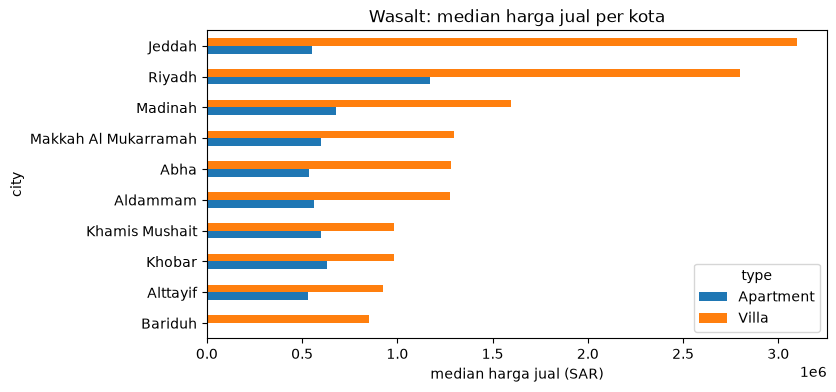

In [26]:
med = (ws[(ws["purpose"] == "sale") & (~ws["price_outlier"])]
       .pivot_table(index="city", columns="type", values="price", aggfunc="median").round(-3))
display(med)

ax = med[["Apartment", "Villa"]].dropna(how="all").sort_values("Villa").plot.barh(figsize=(8, 4))
ax.set_xlabel("median harga jual (SAR)"); ax.set_title("Wasalt: median harga jual per kota")
plt.show()

### 2.8 Kamar, umur bangunan, fasilitas, tanggal tayang

In [27]:
display(ws.groupby("type")[["bedrooms", "bathrooms"]].agg(["min", "median", "max"]))
print("age:", ws["age"].map(type).value_counts().to_dict(), "| contoh:", ws["age"].dropna().unique()[:10].tolist())
amen = Counter(a for lst in ws["amenities"] for a in (lst or []))
print("Iklan tanpa fasilitas:", int((ws["amenities"].map(len) == 0).sum()))
display(pd.Series(amen).sort_values(ascending=False).head(15).rename("iklan"))
pub = pd.to_datetime(ws["published"], errors="coerce", utc=True)
print("published:", pub.min(), "->", pub.max(), "| kosong:", int(pub.isna().sum()))

bedrooms              bathrooms            
                min median   max       min median  max
type                                                  
Apartment       1.0    4.0  45.0       1.0    3.0  4.0
Building        1.0   32.0  90.0       NaN    NaN  NaN
Floor           1.0    6.0   8.0       NaN    NaN  NaN
Land            NaN    NaN   NaN       NaN    NaN  NaN
Rest House      3.0    5.0  50.0       NaN    NaN  NaN
Villa           1.0    7.0  24.0       5.0    6.0  8.0
Warehouse       NaN    NaN   NaN       NaN    NaN  NaN

age: {<class 'str'>: 692, <class 'int'>: 452, <class 'NoneType'>: 163} | contoh: [1, 12, 'New', 11, 8, 6, 5, 9, 4, 10]
Iklan tanpa fasilitas: 1274


2 Separate Entrances    21
Indoor Parking          19
Mosque                  17
School                  12
Retail Outlet           12
Storage Room            12
Yard                    11
Maids Room              10
Park                     9
Indoor Staircase         9
Walk-in Closet           8
Rooftop                  8
Laundry Room             7
Driver Room              7
Health Centre            6
Name: iklan, dtype: int64

published: 2025-11-19 10:18:11.893000+00:00 -> 2026-11-20 00:36:13.007000+00:00 | kosong: 2


### 2.9 Konsistensi nama kota & duplikat

In [28]:
print("ID duplikat:", int(ws["id"].duplicated().sum()))
print("URL duplikat:", int(ws["url"].duplicated().sum()))
print("Nama kota unik:", sorted(ws["city"].dropna().unique()))
print("Jumlah distrik unik:", ws["district"].nunique())

ID duplikat: 0
URL duplikat: 0
Nama kota unik: ['Abha', 'Aldammam', 'Alttayif', 'Bariduh', 'Jeddah', 'Khamis Mushait', 'Khobar', 'Madinah', 'Makkah Al Mukarramah', 'Riyadh']
Jumlah distrik unik: 346


## 3. Ringkasan temuan

Diisi setelah membaca hasil di atas. Hal yang perlu diputuskan untuk chatbot:

- **DarGlobal**: tetap teks bebas (RAG) atau diekstrak jadi tabel? Lihat cakupan di 1.7 dan 1.8.
- **DarGlobal**: bersihkan baris dobel (1.5) dan daftar negara (1.6) sebelum di-index.
- **Wasalt**: aturan outlier harga (2.5), terutama iklan sewa yang harganya tidak masuk akal.
- **Wasalt**: `rent_freq` dibongkar jadi kolom frekuensi (2.4).
- **Wasalt**: normalisasi nama kota (Alttayif → Taif, Aldammam → Dammam, Bariduh → Buraidah).